# Example: Symmetry-reduced Pulse Design Tool

---

This notebook demonstrates how to use `SymmetryReducedSolver` with the **FreeGSNKE Pulse Design Tool** (FPDT) on a self-contained analytic tokamak, evolving the coupled plasma–metal system strictly in the even-in-$Z$ subspace.

Around an up-down symmetric equilibrium in an up-down symmetric machine, the linearised evolution operator $A$ commutes with the up-down reflection $S$:

$$
S^T = S, \qquad S^2 = I, \qquad SA = AS.
$$

Consequently, the even ($+1$) and odd ($-1$) eigenspaces of $S$ are orthogonal and dynamically decoupled. Retaining only the even subspace reproduces the full symmetric linearised dynamics while eliminating fast odd vertical modes.

In this notebook, we:
1. Prepare an exactly up-down symmetric machine description.
2. Construct a symmetric initial Grad-Shafranov equilibrium.
3. Inspect the even and odd passive modes.
4. Run a closed-loop FPDT simulation using `SymmetryReducedSolver`.
5. Verify the parity reduction against both a metal-only reference and a full coupled nonlinear reference.

### 1. Build the analytic source machine

We place active coils and passive structures in reflected pairs about $Z = 0$: four shaping pairs, one symmetric central solenoid, and one odd anti-series vertical-control circuit (included to demonstrate explicit exclusion during preparation). The limiter radius is chosen to avoid landing directly on grid nodes.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from freegsnke import GSstaticsolver, build_machine, equilibrium_update
from freegsnke.inverse import Inverse_optimizer
from freegsnke.jtor_update import Lao85
from freegsnke.up_down_symmetry import prepare_up_down_symmetric_machine


def active_element(r, z, multiplier=100, polarity=1):
    """Return one rectangular active-coil filament bundle."""
    return {
        "R": [r],
        "Z": [z],
        "dR": 0.06,
        "dZ": 0.06,
        "resistivity": 1.55e-8,
        "polarity": polarity,
        "multiplier": multiplier,
    }


def analytic_source_machine():
    """Build an approximately machine-shaped, exactly paired toy description."""
    major_radius = 1.0
    active = {
        "solenoid": {
            **active_element(0.28, 0.0, multiplier=20),
            "R": [0.28] * 4,
            "Z": [-0.55, -0.18, 0.18, 0.55],
        }
    }

    upper_angles = (np.pi / 4, 3 * np.pi / 4, np.pi / 8, 7 * np.pi / 8)
    for index, angle in enumerate(upper_angles, start=1):
        r = major_radius + 0.70 * np.cos(angle)
        z = 0.70 * np.sin(angle)
        active[f"shape_{index}_upper"] = active_element(r, z)
        active[f"shape_{index}_lower"] = active_element(r, -z)

    active["vertical_control"] = {
        "upper": active_element(1.68, 0.28),
        "lower": active_element(1.68, -0.28, polarity=-1),
    }

    passive = []
    for index, angle in enumerate(np.linspace(np.pi / 20, 19 * np.pi / 20, 10)):
        r = major_radius + 0.50 * np.cos(angle)
        z = 0.50 * np.sin(angle)
        half_width = 0.025
        for side, z_centre in (("upper", z), ("lower", -z)):
            passive.append(
                {
                    "name": f"shell_{index}_{side}",
                    "element": f"shell_{index}",
                    "R": np.array(
                        [
                            r - half_width,
                            r + half_width,
                            r + half_width,
                            r - half_width,
                        ]
                    ),
                    "Z": np.array(
                        [
                            z_centre - half_width,
                            z_centre - half_width,
                            z_centre + half_width,
                            z_centre + half_width,
                        ]
                    ),
                    "resistivity": 5.5e-7,
                }
            )

    theta = np.linspace(0.0, 2 * np.pi, 96, endpoint=False)
    limiter = [
        {
            "R": float(major_radius + 0.44 * np.cos(angle)),
            "Z": float(0.44 * np.sin(angle)),
        }
        for angle in theta
    ]
    return active, passive, limiter

### Audit and prepare the machine

The first call uses the default strict policy and intentionally flags the odd active circuit; the second sets `exclude_odd_active=True` to build the symmetric machine and obtain the passive reflection operator.

In [2]:
active_source, passive_source, limiter_source = analytic_source_machine()

try:
    prepare_up_down_symmetric_machine(
        active_source,
        passive_source,
        limiter_data=limiter_source,
        wall_data=limiter_source,
    )
except ValueError as error:
    print("Strict preflight:", error)

prepared = prepare_up_down_symmetric_machine(
    active_source,
    passive_source,
    limiter_data=limiter_source,
    wall_data=limiter_source,
    exclude_odd_active=True,
)
print("Retained even circuits:", prepared.even_active_names)
print("Explicitly excluded odd circuits:", prepared.excluded_odd_active_names)
print("Passive reflection pairs:", len(prepared.passive_pairs))

Strict preflight: Electrically odd active circuits cannot be included in strict even evolution: ('vertical_control',). Pass 'exclude_odd_active=True' to omit and record them explicitly.
Source midplane:             +0.000 mm
Applied whole-machine shift: +0.000 mm
Midplane fit RMS:            nan mm
Matched fit samples:         0
Excluded odd circuits:       ('vertical_control',)
Active reflected pairs:      4
Passive reflected pairs:     10
Component discrepancies (pre-averaging reflected RMS):
  limiter  upper path         / lower path        :   0.000 mm
  wall     upper path         / lower path        :   0.000 mm
  active   shape_1_upper      / shape_1_lower     :   0.000 mm
  active   shape_2_upper      / shape_2_lower     :   0.000 mm
  active   shape_3_upper      / shape_3_lower     :   0.000 mm
  active   shape_4_upper      / shape_4_lower     :   0.000 mm
  active   solenoid           / solenoid          :   0.000 mm
  passive  shell_0_upper      / shell_0_lower     :   0.000

/Users/kpentlan/Documents/Projects/Software/freegsnke/freegsnke/up_down_symmetry.py:897: UserWarning: Limiter changed by intersection with its reflection about Z=0 m: removed 0 m² (0%); 96 -> 150 vertices.
  _warn_boundary_change(original, symmetric, target_midplane, name)
/Users/kpentlan/Documents/Projects/Software/freegsnke/freegsnke/up_down_symmetry.py:897: UserWarning: Wall changed by intersection with its reflection about Z=0 m: removed 0 m² (0%); 96 -> 150 vertices.
  _warn_boundary_change(original, symmetric, target_midplane, name)


### 2. Construct a symmetric initial equilibrium

We build the tokamak from the prepared geometry, reflection-average the discrete machine operators and Green functions so they commute with the reflection map to machine precision, and run a symmetric inverse solve (holding the solenoid current fixed) with reflected upper/lower null constraints.

In [3]:
tokamak = build_machine.tokamak(
    active_coils_data=prepared.even_active_coils_data,
    passive_coils_data=prepared.passive_coils_data,
    limiter_data=prepared.limiter_data,
    wall_data=prepared.wall_data,
)
eq = equilibrium_update.Equilibrium(
    tokamak=tokamak,
    Rmin=0.1,
    Rmax=1.9,
    Zmin=-0.8,
    Zmax=0.8,
    nx=65,
    ny=65,
)

eq._vgreen = prepared.symmetrise_even_machine_greens(eq._vgreen)
tokamak.coil_resist = prepared.symmetrise_even_machine_resistances(
    tokamak.coil_resist
)
tokamak.coil_self_ind = prepared.symmetrise_even_machine_square_operator(
    tokamak.coil_self_ind
)

profiles = Lao85(
    eq=eq,
    Ip=2.0e5,
    fvac=0.5,
    alpha=[58213.6],
    beta=[0.582136],
)
tokamak.set_coil_current("solenoid", 3000.0)
tokamak["solenoid"].control = False

constraints = Inverse_optimizer(
    null_points=[[0.8, 0.8], [0.35, -0.35]],
    isoflux_set=np.array([[[0.8, 0.8, 1.22], [0.35, -0.35, 0.0]]]),
    weight_isoflux=1.0,
    weight_nulls=0.8,
)
static_solver = GSstaticsolver.NKGSsolver(eq)
static_solver.inverse_solve(
    eq=eq,
    profiles=profiles,
    constrain=constraints,
    target_relative_tolerance=1e-5,
    target_relative_psit_update=1e-3,
    l2_reg=np.full(4, 1e-8),
    force_up_down_symmetric=True,
    verbose=False,
)


def selected_lower_xpoint(equilibrium):
    """Select the lower null nearest the inverse-solve target."""
    lower = equilibrium.xpt[equilibrium.xpt[:, 1] < 0]
    target = np.array([0.8, -0.35])
    return lower[np.argmin(np.linalg.norm(lower[:, :2] - target, axis=1)), :2]


def plasma_descriptors(equilibrium):
    """Return the four shape measurements used by the controller."""
    rin, rout = equilibrium.innerOuterSeparatrix()
    rx, zx = selected_lower_xpoint(equilibrium)
    return np.array([rin, rout, rx, zx])


active_coils = list(tokamak.coils_list[: tokamak.n_active_coils])
n_active = len(active_coils)
ctrl_targets = ["Rin", "Rout", "Rx", "Zx"]
print("Active circuit order:", active_coils)
print("Initial active currents [A]:", tokamak.getCurrentsVec()[:n_active])
print("Initial descriptors [m]:", plasma_descriptors(eq))


Active coils --> built from user-provided data.
Passive structures --> built from user-provided data.
Limiter --> built from user-provided data.
Wall --> built from user-provided data.
Magnetic probes --> none provided.
Resistance (R) and inductance (M) matrices --> built using actives (and passives if present).
Tokamak built.
Inverse static solve SUCCESS. Tolerance 5.83e-06 (vs. requested 1e-05) reached in 18/100 iterations.
Active circuit order: ['solenoid', 'shape_1', 'shape_2', 'shape_3', 'shape_4']
Initial active currents [A]: [ 3000.          -455.71083904  5575.09341258  -166.1459215
 -3742.91656536]
Initial descriptors [m]: [ 0.79153908  1.22846475  0.80965718 -0.34977121]


### Symmetry audit

We verify that the machine operators commute with the metal-current reflection $S_m$, the limiter mask is reflection-invariant, and the initial plasma fields and metal currents are even to round-off.

sampled Green functions    : 0.000e+00
inductance operator        : 0.000e+00
resistance operator        : 0.000e+00
plasma flux                : 0.000e+00
toroidal current density   : 0.000e+00
metal currents             : 0.000e+00
limiter-mask defects       : 0


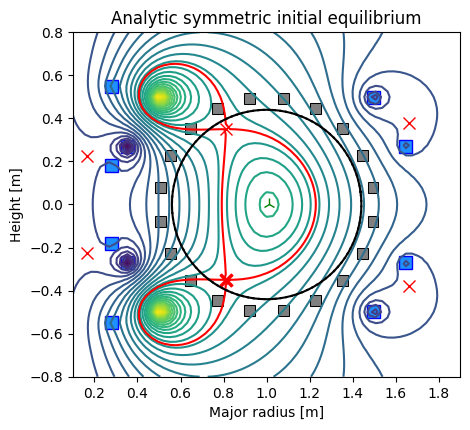

In [4]:
passive_reflection_operator = prepared.passive_reflection_operator
reflection_operator = prepared.even_machine_reflection_operator


def relative_reflection_error(values, parity=1):
    denominator = np.linalg.norm(values)
    if denominator == 0:
        return 0.0
    return np.linalg.norm(values - parity * values[:, ::-1]) / denominator


def relative_commutator_error(matrix):
    numerator = np.linalg.norm(
        reflection_operator @ matrix - matrix @ reflection_operator
    )
    return numerator / np.linalg.norm(matrix)


reflected_greens = np.einsum(
    "ij,jrz->irz", reflection_operator, eq._vgreen[:, :, ::-1]
)
resistance_matrix = np.diag(tokamak.coil_resist)
initial_currents = tokamak.getCurrentsVec()
symmetry_errors = {
    "sampled Green functions": (
        np.linalg.norm(eq._vgreen - reflected_greens)
        / np.linalg.norm(eq._vgreen)
    ),
    "inductance operator": relative_commutator_error(tokamak.coil_self_ind),
    "resistance operator": relative_commutator_error(resistance_matrix),
    "plasma flux": relative_reflection_error(eq.plasma_psi),
    "toroidal current density": relative_reflection_error(profiles.jtor),
    "metal currents": (
        np.linalg.norm(reflection_operator @ initial_currents - initial_currents)
        / np.linalg.norm(initial_currents)
    ),
}
limiter_defects = np.count_nonzero(
    eq.limiter_handler.mask_inside_limiter
    != eq.limiter_handler.mask_inside_limiter[:, ::-1]
)

for name, error in symmetry_errors.items():
    print(f"{name:27s}: {error:.3e}")
print(f"{'limiter-mask defects':27s}: {limiter_defects}")
assert max(symmetry_errors.values()) < 1e-12
assert limiter_defects == 0

fig, axis = plt.subplots(figsize=(5, 5))
eq.plot(axis=axis, show=False)
tokamak.plot(axis=axis, show=False)
axis.set_xlim(0.1, 1.9)
axis.set_ylim(-0.8, 0.8)
axis.set_aspect("equal")
axis.set_title("Analytic symmetric initial equilibrium")
plt.show()


### 3. Build local shape responses for the PCS

Without precomputed virtual circuits, we use four symmetric finite-difference GS solves to form the shape sensitivity matrix

$$
S_{kj} = \frac{\partial s_k}{\partial I_j}
$$

for the four shaping circuits, and take its pseudoinverse $S^+$ to map requested shape corrections to coil-current commands (keeping the solenoid row zero for shape targets).

In [5]:
shape_coils = [name for name in active_coils if name != "solenoid"]
baseline_descriptors = plasma_descriptors(eq)
shape_matrix = np.zeros((len(ctrl_targets), len(shape_coils)))

for column, coil_name in enumerate(shape_coils):
    trial_eq = eq.create_auxiliary_equilibrium()
    trial_profiles = profiles.copy()
    current = trial_eq.tokamak.getCurrentsVec()[
        trial_eq.tokamak.coils_list.index(coil_name)
    ]
    delta_current = max(25.0, 0.01 * abs(current))
    trial_eq.tokamak.set_coil_current(coil_name, current + delta_current)
    static_solver.forward_solve(
        eq=trial_eq,
        profiles=trial_profiles,
        target_relative_tolerance=1e-6,
        force_up_down_symmetric=True,
        suppress=True,
    )
    shape_matrix[:, column] = (
        plasma_descriptors(trial_eq) - baseline_descriptors
    ) / delta_current

shape_vcs = np.linalg.pinv(shape_matrix, rcond=1e-5)
print("Shape-matrix condition number:", np.linalg.cond(shape_matrix))
print("Shape response times pseudo-inverse:")
print(shape_matrix @ shape_vcs)


Shape-matrix condition number: 307.2341992448361
Shape response times pseudo-inverse:
[[ 1.00000000e+00 -3.89329488e-15 -9.82288809e-15 -1.65487594e-14]
 [-6.26153824e-14  1.00000000e+00  4.54909390e-14 -2.99582920e-14]
 [-8.27111175e-15  8.35982046e-16  1.00000000e+00 -4.12220544e-15]
 [ 1.41809314e-14 -1.54823796e-15 -7.46279163e-15  1.00000000e+00]]


### 4. Configure the plasma-control loop

Here we set up the FPDT controllers as in Example 11, holding all references at their initial values so that the controllers act only to reject numerical drift.

In [6]:
from freegsnke.control_loop.pcs import PlasmaControlSystem

tmin = 0.0
tmax = 0.05
waveform_times = np.array([tmin, tmax])
zeros = {"times": waveform_times, "vals": np.zeros(2)}

plasma_data = {
    "ip_ref": {"times": waveform_times, "vals": np.full(2, profiles.Ip)},
    "vloop_ff": zeros,
    "ip_blend": {"times": waveform_times, "vals": np.ones(2)},
    "k_prop": {"times": np.array([tmin]), "vals": np.array([-10.0])},
    "k_int": {"times": np.array([tmin]), "vals": np.array([-20.0])},
    "k_deriv": {"times": np.array([tmin]), "vals": np.array([0.0])},
    "M_solenoid": {"times": np.array([tmin]), "vals": np.array([1.0])},
}

initial_shape = dict(zip(ctrl_targets, baseline_descriptors))
shape_data = {}
for target in ctrl_targets:
    shape_data[target] = {
        "ff": zeros,
        "ref": {
            "times": waveform_times,
            "vals": np.full(2, initial_shape[target]),
        },
        "blend": {"times": waveform_times, "vals": np.ones(2)},
        "k_prop": {"times": np.array([tmin]), "vals": np.array([25.0])},
        "k_int": {"times": np.array([tmin]), "vals": np.array([0.0])},
        "k_deriv": {"times": np.array([tmin]), "vals": np.array([0.0])},
    }

### Virtual circuits and electrical limits

The shape virtual circuits are the columns of $S^+$ (padded with zero on the solenoid), while the plasma-current virtual circuit acts solely on the solenoid. Electrical limits, resistances, and inductances are taken directly from the analytic tokamak object.

In [7]:
circuits_data = {"coil_order": active_coils}
for target_index, target in enumerate(ctrl_targets):
    circuit = np.zeros(n_active)
    circuit[1:] = shape_vcs[:, target_index]
    circuits_data[target] = {"times": np.array([tmin]), "vals": [circuit]}
circuits_data["plasma"] = {
    "times": np.array([tmin]),
    "vals": [np.r_[1.0, np.zeros(n_active - 1)]],
}
for coil_name in active_coils:
    circuits_data[f"{coil_name}_ref"] = zeros

initial_active = tokamak.getCurrentsVec()[:n_active]
current_margin = np.maximum(5000.0, 2.0 * np.abs(initial_active))
systems_data = {
    "min_coil_curr_lims": {
        "times": [tmin],
        "vals": [initial_active - current_margin],
    },
    "max_coil_curr_lims": {
        "times": [tmin],
        "vals": [initial_active + current_margin],
    },
    "max_coil_curr_ramp_lims": {
        "times": [tmin],
        "vals": [1e12 * np.ones(n_active)],
    },
}
for coil_name in active_coils:
    systems_data[f"{coil_name}_pert"] = zeros

pf_data = {
    "R_matrix": {"times": [tmin], "vals": [tokamak.coil_resist[:n_active]]},
    "M_FF_matrix": {
        "times": [tmin],
        "vals": [tokamak.coil_self_ind[:n_active, :n_active]],
    },
    "M_FB_matrix": {
        "times": [tmin],
        "vals": [tokamak.coil_self_ind[:n_active, :n_active]],
    },
    "coil_gains": {
        "times": [tmin],
        "vals": [0.015 * np.ones(n_active)],
    },
    "coil_voltage_lims": {
        "times": np.array([tmin]),
        "vals": [[2000.0] + [750.0] * (n_active - 1)],
    },
    "coil_voltage_slew_lims": {
        "times": [tmin],
        "vals": [1e12 * np.ones(n_active)],
    },
}
vertical_data = {
    "z_ref": {"times": waveform_times, "vals": np.zeros(2)},
    "k_prop": {"times": np.array([tmin]), "vals": np.array([0.0])},
    "k_deriv": {"times": np.array([tmin]), "vals": np.array([0.0])},
}
activation_data = {
    f"{name}_activation": {
        "times": np.array([tmin]),
        "vals": np.array([1.0]),
    }
    for name in active_coils
}

### Assemble the PCS

The standard `PCS` interface is unchanged: symmetry reduction is handled entirely by the evolutive solver.

In [8]:
pcs = PlasmaControlSystem(
    plasma_data=plasma_data,
    shape_data=shape_data,
    shape_control_mode="PID",
    circuits_data=circuits_data,
    systems_data=systems_data,
    pf_data=pf_data,
    vertical_data=vertical_data,
    coil_activation_data=activation_data,
    active_coils=active_coils,
    ctrl_coils=active_coils,
    vertical_coils=[],
    ctrl_targets=ctrl_targets,
    plasma_target=["plasma"],
)

### 5. Initialise the reduced evolutive solver

`SymmetryReducedSolver` enforces symmetric GS solves and removes odd passive modes prior to plasma coupling. With $S_m$ and $S_y$ denoting the metal-current and plasma-grid reflection operators:

$$
S_m^2 = S_y^2 = I, \qquad S_m^T = S_m, \qquad S_m A_m = A_m S_m,
$$

where $A_m = R_m^{-1} L_m$ is the passive circuit operator. The plasma response is projected onto the even subspace via

$$
\Pi_+ = \frac{I + S_y}{2}.
$$

From the 10 reflected passive pairs (10 even and 10 odd modes), we retain 6 even modes alongside the 5 active circuits and $I_p$. Removing the fast odd vertical modes allows a 2.5 ms timestep (compared with 0.5 ms in Example 11).

In [9]:
from freegsnke.symmetry_reduced_solve import SymmetryReducedSolver

stepping = SymmetryReducedSolver(
    eq=eq,
    profiles=profiles,
    GSStaticSolver=static_solver,
    full_timestep=2.5e-3,
    max_internal_timestep=2.5e-3,
    plasma_resistivity=1e-7,
    fix_n_vessel_modes=6,
    plasma_descriptor_function=plasma_descriptors,
    passive_reflection_operator=passive_reflection_operator,
    verbose=False,
)

retained_parity = (
    stepping.evol_metal_curr.normal_modes.passive_mode_parity[
        stepping.evol_metal_curr.selected_modes_mask[n_active:]
    ]
)


def reduced_columns_reflection_error(columns):
    fields = np.zeros((stepping.nx, stepping.ny, columns.shape[1]))
    fields[stepping.limiter_handler.mask_inside_limiter] = columns
    return np.linalg.norm(fields - fields[:, ::-1]) / np.linalg.norm(fields)


print("Retained metal modes:", stepping.n_metal_modes)
print("Retained passive parities:", np.unique(retained_parity))
print("dIydI parity error:", reduced_columns_reflection_error(stepping.dIydI))
print("dIydtheta parity error:", reduced_columns_reflection_error(stepping.dIydtheta))
assert np.all(retained_parity == 1)
assert reduced_columns_reflection_error(stepping.dIydI) < 1e-14
assert reduced_columns_reflection_error(stepping.dIydtheta) < 1e-14


-----
Checking that the provided 'eq' and 'profiles' are a GS solution...
Forward static solve SUCCESS. Tolerance 2.93e-09 (vs. requested 1.00e-08) reached in 3/100 iterations.
-----
Instantiating nonlinear solver objects...
done.
-----
Identifying mode selection criteria...
      'fix_n_vessel_modes' option selected --> passive structure modes that couple most to the strongest passive structure mode are being selected.
-----
Initial mode selection:
   Active coils
      total selected = 5 (out of 5)
   Passive structures
      6 selected using 'fix_n_vessel_modes'
   Total number of modes = 11 (5 active coils + 6 passive structures)
      (Note: some additional modes may be removed after Jacobian calculation if 'mode_removal=True')
-----
Building the 865 x 12 Jacobian (dIy/dI) of plasma current density (inside the LCFS) with respect to all metal currents and the total plasma current.
Building the 865 x 2 Jacobian (dIy/dtheta) of plasma current density (inside the LCFS) with respect to

### Inspect passive-mode parity and truncation

Open markers show all passive modes in the full decomposition; filled markers highlight the even modes retained after parity, coupling, and mode-count selection. The spatial panels show representative even and odd mode current patterns.

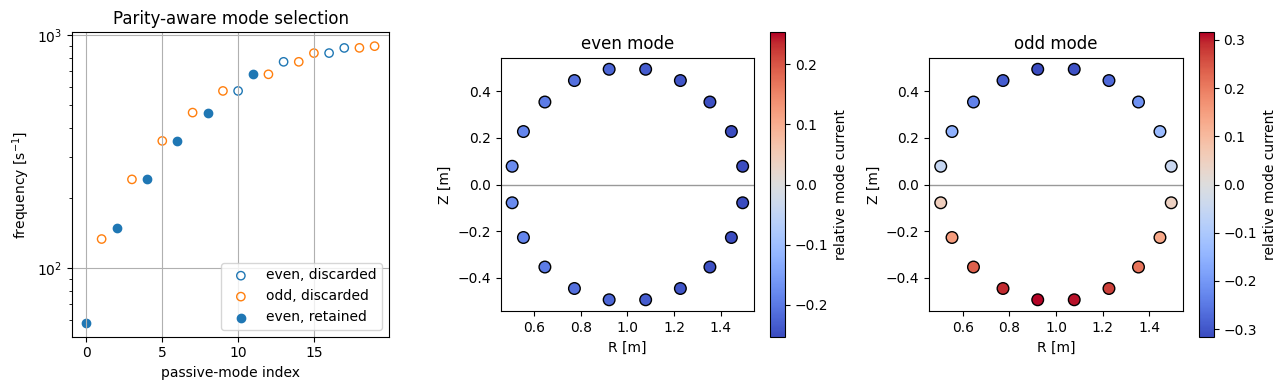

In [10]:
normal_modes = stepping.evol_metal_curr.normal_modes
passive_parity = normal_modes.passive_mode_parity
passive_frequency = normal_modes.w_passive
retained_passive = stepping.evol_metal_curr.selected_modes_mask[n_active:]
passive_centres = np.array(
    [
        [np.mean(element["R"]), np.mean(element["Z"])]
        for element in prepared.passive_coils_data
    ]
)

representative_modes = {
    "even mode": np.flatnonzero(passive_parity > 0)[0],
    "odd mode": np.flatnonzero(passive_parity < 0)[0],
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for parity, label, colour in ((1, "even", "tab:blue"), (-1, "odd", "tab:orange")):
    parity_mask = (passive_parity == parity) & ~retained_passive
    axes[0].scatter(
        np.flatnonzero(parity_mask),
        passive_frequency[parity_mask],
        facecolors="none",
        edgecolors=colour,
        label=f"{label}, discarded",
    )
retained_indices = np.flatnonzero(retained_passive)
axes[0].scatter(
    retained_indices,
    passive_frequency[retained_passive],
    color="tab:blue",
    label="even, retained",
)
axes[0].set_yscale("log")
axes[0].set_xlabel("passive-mode index")
axes[0].set_ylabel("frequency [s$^{-1}$]")
axes[0].set_title("Parity-aware mode selection")
axes[0].grid(True)
axes[0].legend()

for axis, (title, mode_index) in zip(axes[1:], representative_modes.items()):
    amplitudes = normal_modes.Pmatrix[
        n_active:, n_active + mode_index
    ]
    scale = np.max(np.abs(amplitudes))
    points = axis.scatter(
        passive_centres[:, 0],
        passive_centres[:, 1],
        c=amplitudes,
        cmap="coolwarm",
        vmin=-scale,
        vmax=scale,
        s=70,
        edgecolor="k",
    )
    axis.axhline(0.0, color="0.6", linewidth=1)
    axis.set_aspect("equal")
    axis.set_xlabel("R [m]")
    axis.set_ylabel("Z [m]")
    axis.set_title(title)
    fig.colorbar(points, ax=axis, label="relative mode current")

fig.tight_layout()
plt.show()

### 6. Run the controlled evolution

At each 2.5 ms solver step, the PCS runs two 1.25 ms substeps and returns an active-voltage request, which the reduced solver uses to advance the retained metal modes, plasma current, and profile response.

In [11]:
n_steps = 20
dt = stepping.dt_step
dt_pcs = dt / 2
times = tmin + np.arange(n_steps) * dt
stepping.initialize_from_ICs(eq, profiles)

dynamic_psi = np.zeros((*eq.psi().shape, n_steps))
dynamic_currents = np.zeros((len(stepping.vessel_currents_vec), n_steps))
dynamic_ip = np.zeros(n_steps)
dynamic_shape = np.zeros((len(ctrl_targets), n_steps))
dynamic_z = np.zeros(n_steps)
voltages = np.zeros((n_active, n_steps - 1))
step_times = np.zeros(n_steps - 1)

dynamic_psi[:, :, 0] = stepping.eq1.psi()
dynamic_currents[:, 0] = stepping.vessel_currents_vec
dynamic_ip[0] = stepping.profiles1.Ip
dynamic_shape[:, 0] = plasma_descriptors(stepping.eq1)
dynamic_z[0] = stepping.eq1.Zcurrent()

ip_hist_prev = 0.0
ip_err_prev = 0.0
shape_error_prev = np.zeros(len(ctrl_targets))
shape_history_prev = np.zeros(len(ctrl_targets))
approved_current_prev = initial_active.copy()
approved_voltage_prev = np.zeros(n_active)

for index, time_value in enumerate(times[:-1]):
    result = pcs.calculate_ctrl_voltages(
        t=time_value,
        dt=dt_pcs,
        dt_simulator=dt,
        ip_meas=dynamic_ip[index],
        ip_hist_prev=ip_hist_prev,
        ip_err_prev=ip_err_prev,
        T_meas=dynamic_shape[:, index],
        T_err_prev=shape_error_prev,
        T_hist_prev=shape_history_prev,
        I_approved_prev=approved_current_prev,
        I_meas=dynamic_currents[:n_active, index],
        V_approved_prev=approved_voltage_prev,
        zip_meas=dynamic_z[index] * dynamic_ip[index],
        zipv_meas=0.0,
        active_coil_resists=tokamak.coil_resist[:n_active],
        verbose=False,
    )
    (
        approved_voltage,
        ip_hist_prev,
        ip_err_prev,
        shape_error_prev,
        shape_history_prev,
        approved_current_prev,
        active_resistances,
    ) = result
    voltages[:, index] = approved_voltage
    approved_voltage_prev = approved_voltage.copy()

    start = time.perf_counter()
    stepping.nlstepper(
        plasma_resistivity=1e-7,
        active_voltage_vec=approved_voltage,
        # Lao logic adds one dependent closure coefficient to each stored
        # array; the evolutive interface accepts the independent values only.
        profiles_parameters={
            "alpha": profiles.alpha[:-1].copy(),
            "beta": profiles.beta[:-1].copy(),
        },
        custom_active_coil_resistances=active_resistances,
        linear_only=True,
        target_relative_tol_currents=1e-2,
        target_relative_tol_GS=1e-2,
        working_relative_tol_GS=5e-3,
        max_solving_iterations=20,
        relinearise_threshold=0.05,
        no_GS=False,
        verbose=False,
    )
    step_times[index] = time.perf_counter() - start

    dynamic_psi[:, :, index + 1] = stepping.eq1.psi()
    dynamic_currents[:, index + 1] = stepping.vessel_currents_vec
    dynamic_ip[index + 1] = stepping.profiles1.Ip
    dynamic_shape[:, index + 1] = plasma_descriptors(stepping.eq1)
    dynamic_z[index + 1] = stepping.eq1.Zcurrent()

print(f"Mean evolutive-step time: {np.mean(step_times):.3f} s")
print(f"Maximum |Zcurrent|: {np.max(np.abs(dynamic_z)):.3e} m")


Re-linearising around current equilibrium!
   Relative relinearisation criteria change = 5.161% (threshold = 5.0%) 
Building the 865 x 12 Jacobian (dIy/dI) of plasma current density (inside the LCFS) with respect to all metal currents and the total plasma current.
Building the 865 x 2 Jacobian (dIy/dtheta) of plasma current density (inside the LCFS) with respect to all plasma current density profile parameters within Jtor.
Built the 4 x 12 Jacobian (ds/dI) of plasma descriptors with respect to all metal currents and the total plasma current.
Built the 4 x 2 Jacobian (ds/dtheta) of plasma descriptors with respect to all plasma current density profile parameters within Jtor.
Mean evolutive-step time: 0.190 s
Maximum |Zcurrent|: 2.554e-18 m


### 7. Inspect the result

Below we compare the controlled shape and plasma-current trajectories against their reference waveforms, plot the active coil currents and voltages, and verify even parity across the full stored trajectory.

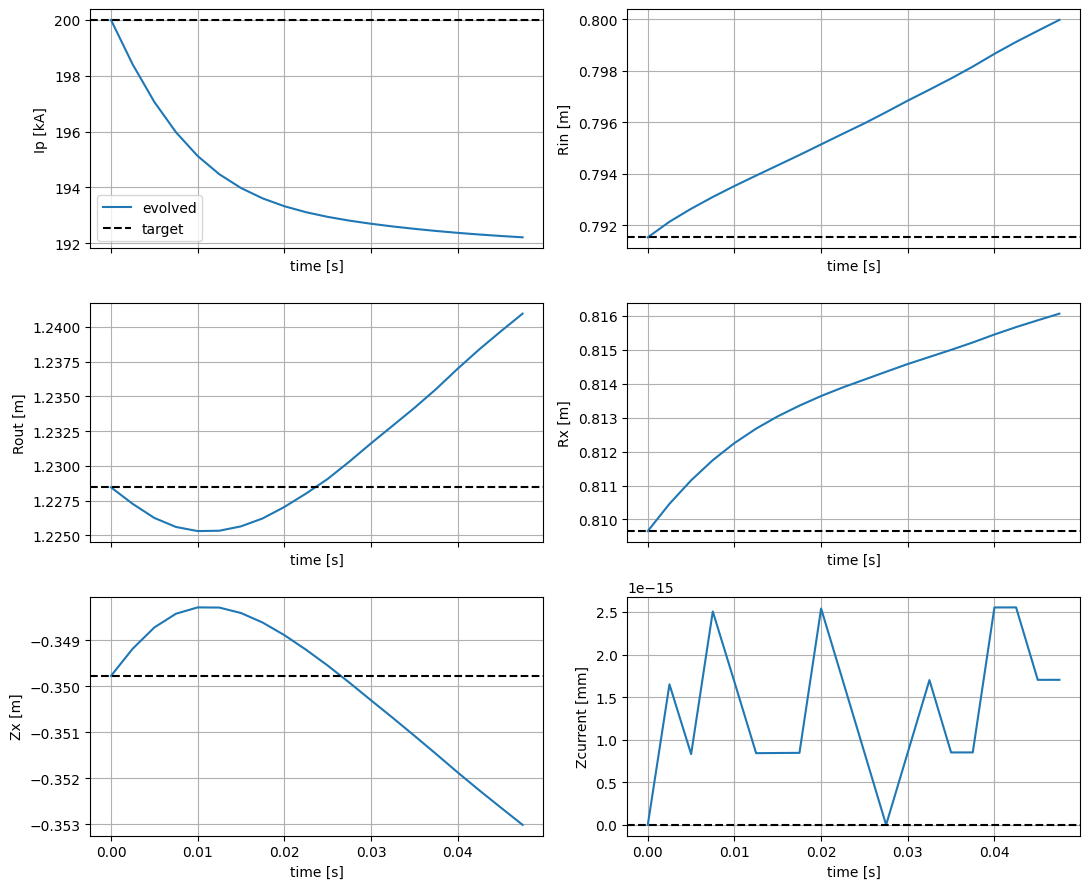

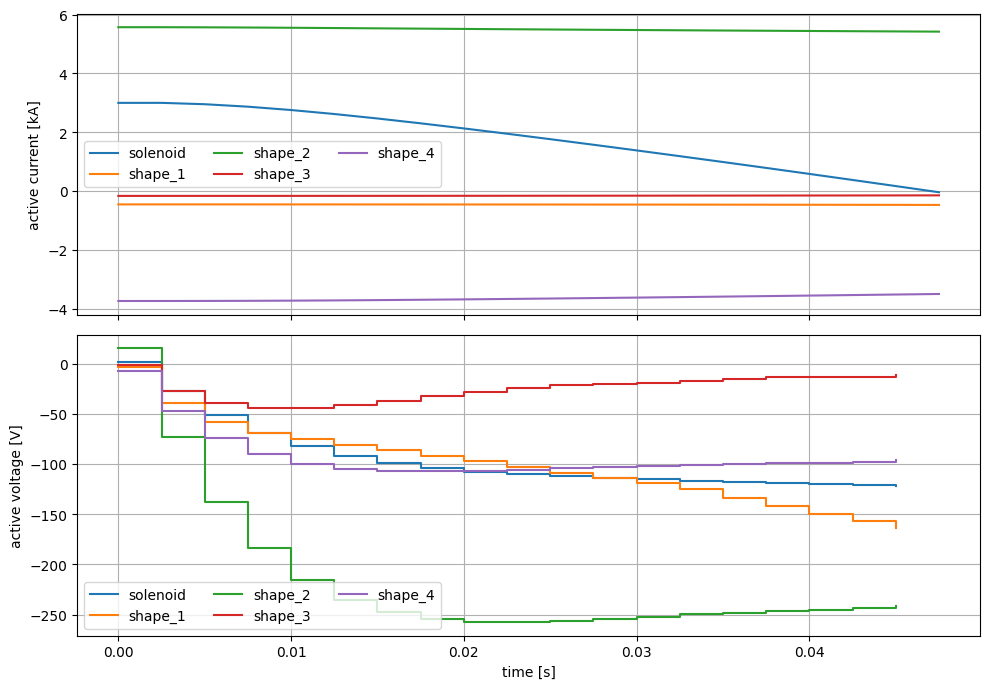

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9), sharex=True)
axes = axes.ravel()
axes[0].plot(times, dynamic_ip / 1e3, label="evolved")
axes[0].axhline(profiles.Ip / 1e3, color="k", linestyle="--", label="target")
axes[0].set_ylabel("Ip [kA]")
axes[0].legend()

for target_index, target in enumerate(ctrl_targets, start=1):
    axis = axes[target_index]
    axis.plot(times, dynamic_shape[target_index - 1], label="evolved")
    axis.axhline(
        baseline_descriptors[target_index - 1],
        color="k",
        linestyle="--",
        label="target",
    )
    axis.set_ylabel(f"{target} [m]")

axes[5].plot(times, 1e3 * dynamic_z)
axes[5].axhline(0.0, color="k", linestyle="--")
axes[5].set_ylabel("Zcurrent [mm]")
for axis in axes:
    axis.grid(True)
    axis.set_xlabel("time [s]")
fig.tight_layout()
plt.show()

fig, (current_axis, voltage_axis) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for coil_index, coil_name in enumerate(active_coils):
    current_axis.plot(
        times,
        dynamic_currents[coil_index] / 1e3,
        label=coil_name,
    )
    voltage_axis.step(
        times[:-1],
        voltages[coil_index],
        where="post",
        label=coil_name,
    )
current_axis.set_ylabel("active current [kA]")
voltage_axis.set_ylabel("active voltage [V]")
voltage_axis.set_xlabel("time [s]")
for axis in (current_axis, voltage_axis):
    axis.grid(True)
    axis.legend(ncol=3)
fig.tight_layout()
plt.show()


In [13]:
flux_parity_errors = [
    relative_reflection_error(dynamic_psi[:, :, index])
    for index in range(n_steps)
]
current_parity_errors = []
for index in range(n_steps):
    current = dynamic_currents[:, index]
    denominator = np.linalg.norm(current)
    current_parity_errors.append(
        0.0
        if denominator == 0
        else np.linalg.norm(reflection_operator @ current - current) / denominator
    )

print("Maximum flux parity error:", max(flux_parity_errors))
print("Maximum metal-current parity error:", max(current_parity_errors))
print(
    "Largest descriptor departure [mm]:",
    1e3 * np.max(np.abs(dynamic_shape - baseline_descriptors[:, None]), axis=1),
)
print(
    "Largest active-current departure [A]:",
    np.max(
        np.abs(dynamic_currents[:n_active] - initial_active[:, None]),
        axis=1,
    ),
)
assert max(flux_parity_errors) < 1e-12
assert max(current_parity_errors) < 1e-12


Maximum flux parity error: 2.190521076046951e-17
Maximum metal-current parity error: 0.0
Largest descriptor departure [mm]: [ 8.43894728 12.49155635  6.40780413  3.23912779]
Largest active-current departure [A]: [3041.72641073   17.74198016  150.37943473   18.07889279  238.8004593 ]


### 8. Verify the metal-only reduction

As a direct check of the passive parity reduction, we evolve the linear metal circuit twice—once with all passive modes and once with only the even passive modes—starting from the same even currents and voltages. Since the circuit operator commutes with reflection, the physical currents must agree.

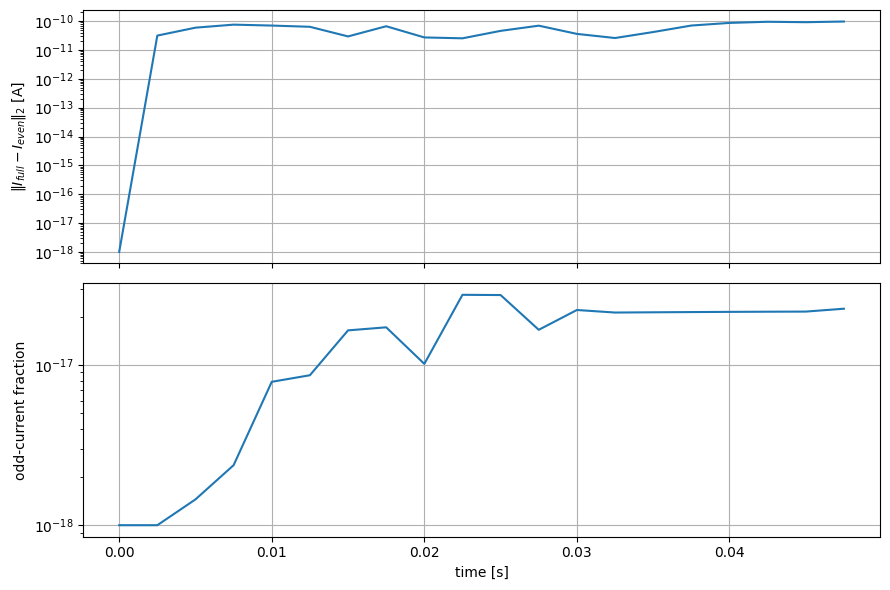

Maximum physical-current difference [A]: 9.723609398042063e-11
Maximum odd-current fraction: 2.7486901728727782e-17


In [14]:
from freegsnke.circuit_eq_metal import metal_currents


def make_metal_reference(remove_odd_modes):
    return metal_currents(
        eq=eq,
        flag_vessel_eig=True,
        flag_plasma=False,
        max_mode_frequency=np.inf,
        max_internal_timestep=dt,
        full_timestep=dt,
        coil_resist=tokamak.coil_resist,
        coil_self_ind=tokamak.coil_self_ind,
        passive_reflection_operator=passive_reflection_operator,
        remove_odd_passive_modes=remove_odd_modes,
        verbose=False,
    )


full_metal = make_metal_reference(remove_odd_modes=False)
even_metal = make_metal_reference(remove_odd_modes=True)
physical_initial = dynamic_currents[:, 0]
full_state = full_metal.Pm1 @ physical_initial
even_state = even_metal.Pm1 @ physical_initial

full_physical = [physical_initial.copy()]
even_physical = [physical_initial.copy()]
odd_fraction = [0.0]
for voltage in voltages.T:
    full_state = full_metal.stepper(full_state, voltage)
    even_state = even_metal.stepper(even_state, voltage)
    full_current = full_metal.P @ full_state
    even_current = even_metal.P @ even_state
    full_physical.append(full_current)
    even_physical.append(even_current)
    odd_part = 0.5 * (
        full_current - reflection_operator @ full_current
    )
    odd_fraction.append(
        np.linalg.norm(odd_part) / max(np.linalg.norm(full_current), 1.0)
    )

full_physical = np.asarray(full_physical).T
even_physical = np.asarray(even_physical).T
physical_difference = np.linalg.norm(
    full_physical - even_physical, axis=0
)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].semilogy(times, np.maximum(physical_difference, 1e-18))
axes[0].set_ylabel(r"$\|I_{full}-I_{even}\|_2$ [A]")
axes[1].semilogy(times, np.maximum(odd_fraction, 1e-18))
axes[1].set_ylabel("odd-current fraction")
axes[1].set_xlabel("time [s]")
for axis in axes:
    axis.grid(True)
fig.tight_layout()
plt.show()

print("Maximum physical-current difference [A]:", np.max(physical_difference))
print("Maximum odd-current fraction:", np.max(odd_fraction))
assert np.max(physical_difference) < 1e-9
assert np.max(odd_fraction) < 1e-12

### 9. Compare coupled nonlinear evolution

Finally, we restart from copies of the initial equilibrium and run three 2.5 ms coupled nonlinear steps (`linear_only=False`, `no_GS=False`) with a 0.2 V step on the solenoid. We compare `SymmetryReducedSolver` (10 even passive modes) against `nl_solver` with `force_up_down_symmetric=True` and `remove_odd_passive_modes=False` (all 20 passive modes), verifying that both produce matching metal currents, $I_p$, and flux parity.

-----
Checking that the provided 'eq' and 'profiles' are a GS solution...
Forward static solve SUCCESS. Tolerance 2.93e-09 (vs. requested 1.00e-08) reached in 0/100 iterations.
-----
Instantiating nonlinear solver objects...
done.
-----
Identifying mode selection criteria...
      'fix_n_vessel_modes' option selected --> passive structure modes that couple most to the strongest passive structure mode are being selected.
-----
Initial mode selection:
   Active coils
      total selected = 5 (out of 5)
   Passive structures
      10 selected using 'fix_n_vessel_modes'
   Total number of modes = 15 (5 active coils + 10 passive structures)
      (Note: some additional modes may be removed after Jacobian calculation if 'mode_removal=True')
-----
Building the 865 x 16 Jacobian (dIy/dI) of plasma current density (inside the LCFS) with respect to all metal currents and the total plasma current.
Building the 865 x 2 Jacobian (dIy/dtheta) of plasma current density (inside the LCFS) with respect 

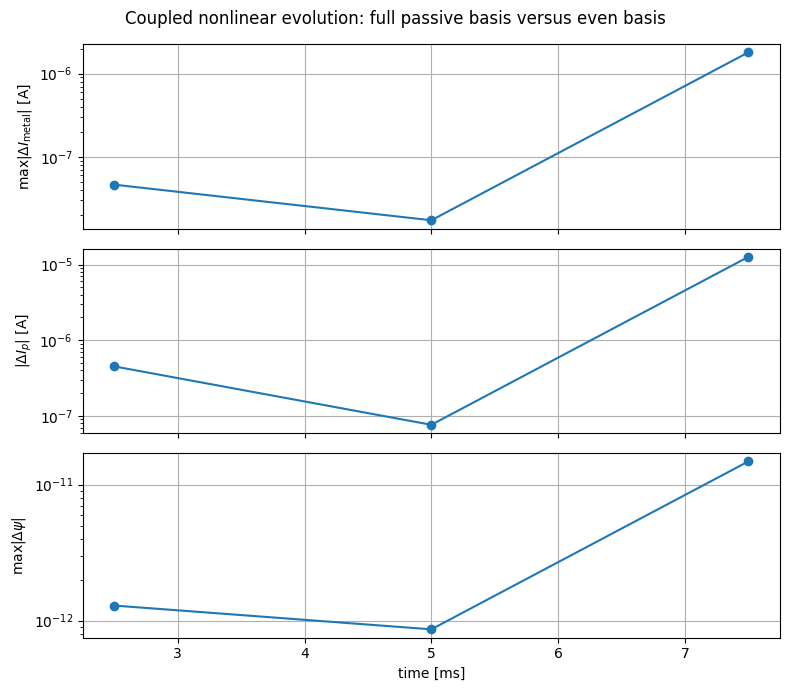

Maximum relative flux/jtor parity errors: [1.95636204e-17 1.43615137e-16]


In [15]:
from freegsnke.nonlinear_solve import nl_solver

n_passive = len(prepared.passive_names)
even_passive_projector = (np.eye(n_passive) + passive_reflection_operator) / 2
n_even_passive = int(round(np.trace(even_passive_projector)))
nonlinear_options = dict(
    GSStaticSolver=static_solver,
    passive_reflection_operator=passive_reflection_operator,
    full_timestep=2.5e-3,
    max_internal_timestep=2.5e-3,
    plasma_resistivity=1e-7,
    plasma_descriptor_function=plasma_descriptors,
    verbose=False,
)
reduced_solver = SymmetryReducedSolver(
    eq=eq.create_auxiliary_equilibrium(),
    profiles=profiles.copy(),
    fix_n_vessel_modes=n_even_passive,
    **nonlinear_options,
)
reference_solver = nl_solver(
    eq=eq.create_auxiliary_equilibrium(),
    profiles=profiles.copy(),
    force_up_down_symmetric=True,
    remove_odd_passive_modes=False,
    fix_n_vessel_modes=n_passive,
    **nonlinear_options,
)
print(
    "Reduced/reference metal modes:",
    reduced_solver.n_metal_modes,
    reference_solver.n_metal_modes,
)

nonlinear_voltage = np.zeros(n_active)
nonlinear_voltage[active_coils.index("solenoid")] = 0.2
# As above, pass only the independent Lao85 coefficients, excluding closure.
nonlinear_profile_parameters = {
    "alpha": profiles.alpha[:-1].copy(),
    "beta": profiles.beta[:-1].copy(),
}
nonlinear_errors = []
nonlinear_parity_errors = []
for step in range(3):
    for solver in (reduced_solver, reference_solver):
        solver.nlstepper(
            active_voltage_vec=nonlinear_voltage,
            profiles_parameters=nonlinear_profile_parameters,
            linear_only=False,
            no_GS=False,
            target_relative_tol_currents=1e-5,
            target_relative_tol_GS=1e-5,
            working_relative_tol_GS=1e-6,
            max_solving_iterations=20,
            verbose=False,
        )
        nonlinear_parity_errors.append(
            [
                relative_reflection_error(solver.eq1.psi()),
                relative_reflection_error(solver.profiles1.jtor),
            ]
        )
    nonlinear_errors.append(
        [
            np.max(
                np.abs(
                    reduced_solver.vessel_currents_vec
                    - reference_solver.vessel_currents_vec
                )
            ),
            abs(reduced_solver.profiles1.Ip - reference_solver.profiles1.Ip),
            np.max(np.abs(reduced_solver.eq1.psi() - reference_solver.eq1.psi())),
        ]
    )

nonlinear_errors = np.asarray(nonlinear_errors)
nonlinear_parity_errors = np.asarray(nonlinear_parity_errors)
nonlinear_times = 1e3 * reduced_solver.dt_step * np.arange(1, 4)
error_labels = [
    r"$\max|\Delta I_\mathrm{metal}|$ [A]",
    r"$|\Delta I_p|$ [A]",
    r"$\max|\Delta\psi|$",
]
fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for column, (ax, label) in enumerate(zip(axes, error_labels)):
    ax.semilogy(nonlinear_times, np.maximum(nonlinear_errors[:, column], 1e-18), "o-")
    ax.set_ylabel(label)
    ax.grid(True)
axes[-1].set_xlabel("time [ms]")
fig.suptitle("Coupled nonlinear evolution: full passive basis versus even basis")
fig.tight_layout()
plt.show()

print("Maximum relative flux/jtor parity errors:", nonlinear_parity_errors.max(axis=0))
assert np.isfinite(nonlinear_errors).all()
assert np.isfinite(nonlinear_parity_errors).all()
assert np.max(nonlinear_errors[:, 0]) < 1e-3  # A, physical metal currents
assert np.max(nonlinear_errors[:, 1]) < 1e-3  # A, total plasma current
assert np.max(nonlinear_errors[:, 2]) < 1e-8
assert np.max(nonlinear_parity_errors) < 1e-12
